# Final deliverable: delivery route optimization (CVRP and CVRPTW)

**CesiCDP for the ADEME Smart Multimodal Mobility call.** Team: Pablo, Dag, Farida.

*One depot, identical trucks, customers with a demand and a time window, travel times that depend
on the hour: which truck serves which customers, in which order, so that the total route duration
is minimal?* The problem is NP-hard (section 2); the exact model solves it up to 7 or 8 customers
with traffic and up to 100 customers on easy instances without traffic (section 4). Of three
metaheuristics compared on 50 Solomon test instances at equal time (6 more for tuning), **GRASP-ILS** is the best, with
a mean gap of 1.16 % to the best known solutions (section 8).

| Section | Content | Author |
| --- | --- | --- |
| 1 to 4 | data, complexity, ILP, exact approach | Pablo |
| 5 to 7 | chosen metaheuristic, implementation, test cases | Farida (GRASP), written up by Pablo |
| 8 | experimental study of Tabu Search (Pablo), SA (Dag), GRASP-ILS (Farida) | Pablo |
| 9, 10 | limitations, references | all |

Run from the repository root or `notebooks/`, after `pip install -e ".[dev]"`; sections 4 and 8 read
the CSV files written by `experiments/exact_study.py` (about 30 min) and
`experiments/solomon_study.py` (about 1.5 h on 7 cores); the other cells take about 1 min.

## Contents

| | Section | What it answers |
| --- | --- | --- |
| 1 | [Data formalization](#s1) | which data the problem reads, and what the model decides |
| 2 | [Complexity](#s2) | why no fast exact algorithm is expected (NP-hard) |
| 3 | [Complete ILP](#s3) | the model, constraint by constraint, and the code that solves it |
| 4 | [Exact approach in practice](#s4) | up to which size the ILP proves the optimum |
| 5 | [Chosen metaheuristic: GRASP-ILS](#s5) | how the chosen method works, and the two others |
| 6 | [Implementation](#s6) | the method running on three instances |
| 7 | [Test cases](#s7) | how we know the code is right |
| 8 | [Experimental study](#s8): [tuning](#s81), [results](#s82), [tests](#s83) | which method is best, with statistics |
| 9 | [Limitations and improvements](#s9) | what is not covered yet |
| 10 | [References](#s10) | sources |
| A | [Glossary of symbols](#sA) | every symbol of the notebook in one table |

<a id="s1"></a>
## 1. Data formalization

The road network is reduced to a **complete directed graph** on the depot and the customers; the
time of a trip $i \to j$ is the fastest path in the network, computed once. The depot appears
twice, node $0$ (departure) and node $n + 1$ (return), so each truck has a departure and a return
time. All times are minutes after midnight.

| Symbol | Meaning | Unit |
| --- | --- | --- |
| $V^+ = \{1, \dots, n\}$ | customers | |
| $V = \{0\} \cup V^+ \cup \{n+1\}$ | nodes; $0$ and $n+1$ are the depot | |
| $A$ | trips: depot to customer, customer to customer, customer to depot, and $0 \to n+1$ (truck not used) | |
| $\mathcal{K} = \{1, \dots, K\}$ | identical trucks | |
| $\mathcal{H} = \{0, \dots, 23\}$ | hours of the day | |
| $Q$ | capacity of a truck | units |
| $q_i$ | demand of customer $i$ ($q_i \le Q$) | units |
| $[e_i, l_i]$ | time window: service must **start** in it | min |
| $s_i$ | service time at customer $i$ ($s_0 = 0$) | min |
| $[e_0, l_0]$ | working day of the depot | min |
| $c_{ij}$ | travel time from $i$ to $j$ on empty roads | min |
| $\rho_h$ | traffic intensity of hour $h$ ($\rho_h \ge 1$) | |
| $c_{ij}^h = \rho_h \, c_{ij}$ | **traffic matrix**: travel time when leaving $i$ during hour $h$ | min |

The $\rho_h$ values (peaks 1.75 to 1.80 from 7:00 to 9:00 and from 17:00 to 19:00, 1.00 at night)
are assumptions of notebook 01, to be replaced by measured data. The model only reads numbers from
the matrix, so measured values change no equation.

**Decision variables**

| Variable | Domain | Meaning |
| --- | --- | --- |
| $x_{ij}^k$ | $\{0, 1\}$ | truck $k$ drives directly from $i$ to $j$ |
| $y_{ih}$, $y_{0h}^k$ | $\{0, 1\}$ | the truck leaves customer $i$ (the depot, for truck $k$) during hour $h$ |
| $t_0^k$, $t_{n+1}^k$ | $\ge 0$, min | truck $k$ leaves the depot, is back |
| $a_i$, $w_i$, $t_i$ | $\ge 0$, min | arrival, waiting and service start at customer $i$ |

The travel time is fixed by the hour of departure, so a later departure may arrive earlier (the
first in, first out property is not guaranteed): an accepted simplification.

**Benchmark data.** The Solomon instances (56 files, 100 customers, PyVRP/VRPLIB copy) give
$c_{ij}$ as Euclidean distances truncated to one decimal, the convention of their best known
values, and no traffic ($\rho_h = 1$).

<a id="s2"></a>
## 2. Complexity

**Decision version (DEC).** Given an instance and a number $B$, is there a feasible plan of total
route duration at most $B$?

**DEC is in NP.** A certificate is the list of routes with each truck's departure time (a rational
of polynomial size: an optimal departure can be taken at a breakpoint of the piecewise linear
schedule). Checking
that every customer appears once, that each load is at most $Q$, and computing the schedule along
each route (one matrix read, one comparison per visit) takes $O(n + K)$ operations; comparing the
total with $B$ is one more.

**Hamiltonian cycle reduces to DEC.** Let $G = (U, E)$ be a graph with $U = \{u_0, \dots, u_m\}$,
$m \ge 2$. Build in $O(m^2)$ the instance: depot $u_0$, customers $u_1, \dots, u_m$, $K = 1$,
$q_i = 1$, $Q = m$, $s_i = 0$, every window equal to the whole day, $\rho_h = 1$ for every $h$,
$c_{ij} = 1/(m+1)$ minute if $\{u_i, u_j\} \in E$ and $c_{ij} = 2/(m+1)$ otherwise, and $B = 1$
(so every plan fits in the day whatever $m$).

- If $G$ has a Hamiltonian cycle, start it at $u_0$: the truck follows it, each of its $m + 1$
  trips takes $1/(m+1)$, no window makes it wait, so the duration is $1 \le B$.
- If a plan has duration at most $1$: the single truck visits the $m$ customers once each and
  returns, so its route is a cycle through all $m + 1$ nodes made of $m + 1$ trips. Each trip takes
  at least $1/(m+1)$, so all of them take exactly $1/(m+1)$, and each one is an edge of $G$: the
  route is a Hamiltonian cycle of $G$.

Hamiltonian cycle is NP-complete (Karp, 1972), so DEC is **NP-complete** and the optimization
problem is **NP-hard**. The instance built uses only the special case $K = 1$, $\rho_h = 1$, wide
windows, which is the travelling salesman problem: capacity, windows and traffic add constraints
to a problem that is already hard. Capacity alone is hard too: deciding whether $K$ trucks can
carry the demands is bin packing (Garey and Johnson, 1979).

**Consequence.** No polynomial exact algorithm is expected. Section 4 measures where the exact ILP
stops being usable; sections 5 to 8 use metaheuristics for the realistic sizes.

<a id="s3"></a>
## 3. Complete ILP

$$
\begin{aligned}
\min \quad & z = \sum_{k \in \mathcal{K}} \big( t_{n+1}^k - t_0^k \big) \\[4pt]
\text{s.t.} \quad
& \sum_{k} \sum_{j : (i, j) \in A} x_{ij}^k = 1 && \forall i \in V^+ && \text{(1) each customer served once}\\
& \sum_{j} x_{0j}^k = 1, \quad \sum_{i} x_{i, n+1}^k = 1 && \forall k && \text{(2), (4) each truck leaves and returns}\\
& \sum_{i} x_{ij}^k = \sum_{i} x_{ji}^k && \forall j \in V^+,\ k && \text{(3) a truck that enters leaves}\\
& \sum_{i \in V^+} q_i \sum_{j} x_{ij}^k \le Q && \forall k && \text{(5) capacity}\\
& \sum_h y_{ih} = 1, \quad \sum_h 60h\, y_{ih} \le t_i + s_i \le \sum_h 60(h+1)\, y_{ih} && \forall i \in V^+ && \text{(6), (7) departure hour}\\
& \sum_h y_{0h}^k = 1, \quad \sum_h 60h\, y_{0h}^k \le t_0^k \le \sum_h 60(h+1)\, y_{0h}^k && \forall k && \text{(6), (7) at the depot}\\
& \Big\lvert\, a_j^k - t_i^k - s_i - \sum_h c_{ij}^h\, y_{ih}^k \,\Big\rvert \le M (1 - x_{ij}^k) && \forall (i, j) \in A,\ k && \text{(8) arrival with traffic}\\
& t_i = a_i + w_i, \quad e_i \le t_i \le l_i && \forall i \in V^+ && \text{(9), (10) wait, then serve}\\
& t_0^k \ge e_0, \quad t_{n+1}^k \le l_0 && \forall k && \text{(10) working day}\\
& x,\ y \in \{0, 1\}, \quad a,\ w,\ t \ge 0 && && \text{(11)}
\end{aligned}
$$

Shorthands in (8): $t_i^k$ is $t_i$ at a customer and $t_0^k$ at the depot, $a_j^k$ is $a_j$ at a
customer and $t_{n+1}^k$ at the return, $y_{ih}^k$ is $y_{ih}$ at a customer and $y_{0h}^k$ at the
depot. $M = 2880$ (two days) exceeds every possible value of
$\lvert a_j - t_i - s_i - c_{ij}^h \rvert$ within a working day, so (8) is inactive when
$x_{ij}^k = 0$. The absolute value stands for two linear inequalities; since $c_{ij}^h + s_i > 0$,
times increase along a route and (8) also forbids subtours. $w_i$ is kept so that the waiting
appears in the solution; it could be replaced by $t_i \ge a_i$. Every line is linear: the model is a mixed
integer linear program with $K \lvert A \rvert$ variables $x$, $24 (n + K)$ variables $y$ and
$3n + 2K$ real variables.

**Reading the model line by line.** A sum $\sum_{k}$ adds over the trucks, $\sum_{j : (i,j) \in A}$
over the allowed next stops after $i$, $\sum_h$ over the hours of the day; $\forall$ means the line
is written once for each element of the set.

| Line | In words | Why it is needed |
| --- | --- | --- |
| objective | add, over the trucks, return time minus departure time | the brief asks for the minimum total route duration; one component |
| (1) | for each customer, exactly one arc leaves it, over all trucks | every customer is served, once, by one truck |
| (2) | each truck takes exactly one arc out of the depot (possibly $0 \to n+1$, unused) | each truck has one route; fewer than $K$ trucks are allowed |
| (3) | for each customer and truck, arcs in = arcs out | a truck that reaches a customer leaves it: routes are paths |
| (4) | each truck takes exactly one arc into the return depot | every route ends at the depot |
| (5) | the demands of the customers truck $k$ leaves from add up to at most $Q$ | the load of a truck, full at departure, fits its capacity |
| (6) | exactly one departure hour per stop | picks which value of the traffic matrix applies |
| (7) | the departure time lies inside that hour | ties the hour $h$ to the clock time |
| (8) | if truck $k$ drives $i \to j$, arrival at $j$ = departure from $i$ + travel time of the departure hour | traffic enters the times; switched off by $M$ when the arc is unused; forbids subtours |
| (9) | service start = arrival + waiting | a truck may wait for a window to open |
| (10) | service starts inside the window; trucks work inside the day | time windows and working day |
| (11) | $x, y$ binary, times non-negative | domains |

**What the code solves** (`src/cvrp/ilp.py`)

| Function | Model | Used for |
| --- | --- | --- |
| `solve_tdvrptw` | the model above, constraints (1) to (11) | exact optimum with traffic, small $n$ |
| `solve_cvrptw` | benchmark variant: $\rho_h = 1$, two-index $x_{ij}$, objective replaced by total distance $\sum c_{ij} x_{ij}$ | the Solomon benchmark |
| `solve_cvrp_flow`, `_rcc`, `_mtz` | the same variant without windows | CVRP, lower bounds |

The Solomon best known values minimize **total distance** with travel time equal to distance and
no traffic. With $\rho_h = 1$ our objective equals that distance plus the service times (a
constant) plus the waiting, so the benchmark variant optimizes our objective without its waiting
term: it measures the routing part of the model, the only one for which published optima exist. The metaheuristics take the route cost as a function, so the
same search runs on the duration with traffic (`cvrp.tabu.duration_cost`, GRASP
`objective="duration"`).

The cell below solves the model on the toy instance of notebook 01 and compares it with an
enumeration of every partition, visiting order and departure time (0.25 min steps).

In [1]:
import itertools
import sys
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "experiments"))  # used from section 6 on

from cvrp import Instance
from cvrp.ilp import solve_tdvrptw
from cvrp.tabu import RHO

coords = np.array([[0, 0], [1, 0], [2, 0], [0, 1], [0, 2], [-1, 0], [0, -1]], dtype=float)
q = np.array([0, 4, 4, 3, 3, 5, 5])
e = np.array([360, 480, 480, 420, 540, 600, 600], dtype=float)
l = np.array([1200, 540, 660, 480, 600, 840, 840], dtype=float)
s = np.array([0, 10, 10, 10, 10, 10, 10], dtype=float)
c = 10 * np.linalg.norm(coords[:, None] - coords[None], axis=2)
toy = Instance("toy", coords, q, capacity=10, num_vehicles=3, ready_times=e, due_times=l,
               service_times=s, dist=c)
res = solve_tdvrptw(toy, RHO, time_limit=60)


def duration(route, t0):
    # Route duration leaving the depot at t0, or None if a window is missed.
    i, t = 0, t0
    for j in route + [0]:
        leave = t + s[i]
        arrive = leave + RHO[int(leave // 60)] * c[i, j]
        if j == 0:
            return arrive - t0 if arrive <= l[0] else None
        t = max(arrive, e[j])
        if t > l[j]:
            return None
        i = j


@lru_cache(None)
def best_route(customers):
    if q[list(customers)].sum() > toy.capacity:
        return np.inf
    return min((d for p in itertools.permutations(customers) for t0 in np.arange(e[0], l[0], 0.25)
                if (d := duration(list(p), t0)) is not None), default=np.inf)


def partitions(items, k):
    if not items:
        yield []
        return
    for p in partitions(items[1:], k):
        for i in range(len(p)):
            yield p[:i] + [p[i] + [items[0]]] + p[i + 1:]
        if len(p) < k:
            yield p + [[items[0]]]


enum = min(sum(best_route(tuple(sorted(r))) for r in p) for p in partitions(list(range(1, 7)), 3))
print(f"ILP (constraints 1 to 11): {res.status}, z = {res.objective:.2f} min, routes "
      f"{res.solution.routes}, {res.n_vars} variables, {res.seconds:.1f} s")
print(f"enumeration: z = {enum:.2f} min; hand solution of notebook 01: 256.50 min")

ILP (constraints 1 to 11): Optimal, z = 247.16 min, routes [[4, 2], [3, 1], [6, 5]], 369 variables, 1.3 s
enumeration: z = 247.16 min; hand solution of notebook 01: 256.50 min


The ILP and the enumeration agree on the optimum: the code optimizes the model as written. It is
9 minutes shorter than the hand solution of notebook 01, which paired the customers differently.

<a id="s4"></a>
## 4. Exact approach in practice

**Question.** Up to which size does the ILP prove the optimum, and how good are its bounds?
`experiments/exact_study.py` solves growing sub-instances (the depot and the first $n$ customers)
with HiGHS on one thread and a 60 s limit per solve, and writes `results/exact_*.csv`:

| Experiment | Instances | Model |
| --- | --- | --- |
| 4.1 | A-n32-k5, B-n31-k5, $n = 6$ to 16 | CVRP, three formulations (MTZ, flow, capacity cuts) |
| 4.2 | Solomon C101, R101, RC101, $n = 5$ to 100 | benchmark variant (distance, $\rho_h = 1$), with one Tabu Search run of 5 s as upper bound |
| 4.3 | Solomon C101, R101, RC101, $n = 3$ to 10, time 0 at 8:00 | the model of section 3, with $\mathcal{H}$ extended to two days ($\{0, \dots, 47\}$, same $\rho_h$ each day) because the C101 day ends after midnight |

The three CVRP formulations add to the two-index core ($x_{ij}$, degrees, fleet) one way to forbid
subtours and overloads: **MTZ**, a load $u_j \ge u_i + q_j - Q(1 - x_{ij})$ with
$q_i \le u_i \le Q$; **flow**, a load on board $f_{ij}$ with $q_j x_{ij} \le f_{ij} \le (Q - q_i) x_{ij}$
and $\sum_i f_{ij} - \sum_k f_{jk} = q_j$; **capacity cuts**,
$\sum_{i \notin S, j \in S} x_{ij} \ge \lceil q(S) / Q \rceil$ for the sets $S$ found violated, added round
by round.

The **root gap** is $100\,(z^* - z_{LP}) / z^*$, where $z^*$ is the best integer value and $z_{LP}$
the LP relaxation (for capacity cuts, the root LP with its cuts).

,proven_optimal,runs,median_s,mean_root_gap
model,,,,
MTZ,6,12,42.57,50.05
capacity cuts,12,12,0.03,0.57
flow,12,12,1.34,22.55


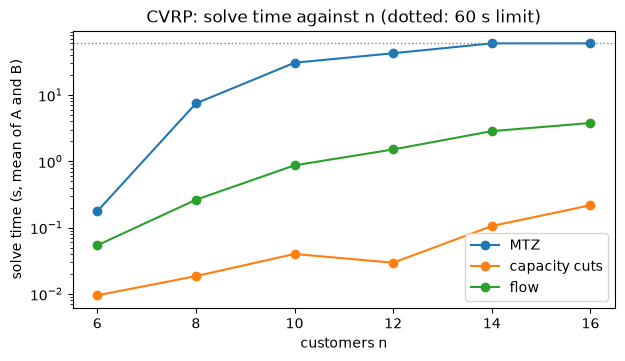

In [2]:
import matplotlib.pyplot as plt

RES = ROOT / "results"
cvrp = pd.read_csv(RES / "exact_cvrp.csv")
tw = pd.read_csv(RES / "exact_cvrptw.csv")
td = pd.read_csv(RES / "exact_traffic.csv")
for df in (cvrp, tw, td):
    df["root_gap"] = (100 * (df.objective - df.lp_bound) / df.objective).clip(lower=0)
    df["optimal"] = df.status.eq("Optimal")

t41 = cvrp.groupby("model").agg(
    proven_optimal=("optimal", "sum"),
    runs=("optimal", "size"),
    median_s=("seconds", "median"),
    mean_root_gap=("root_gap", "mean"),
)
display(t41.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for model, g in cvrp.groupby("model"):
    m = g.groupby("n").seconds.mean()
    ax.plot(m.index, m.values, marker="o", label=model)
ax.axhline(60, color="grey", ls=":", lw=1)
ax.set(yscale="log", xlabel="customers n", ylabel="solve time (s, mean of A and B)",
       title="CVRP: solve time against n (dotted: 60 s limit)")
ax.legend()
plt.show()

**Reading 4.1.** The capacity cut formulation proves every optimum (12 of 12) in at most 0.35 s,
because its LP relaxation is almost tight (mean root gap 0.6 %); the flow formulation also proves
all of them, in at most 4.4 s; MTZ, whose relaxation is far from the optimum (root gap 50 %), stops
at the 60 s limit from $n = 10$ on clustered B and $n = 14$ on random A. The strength of the LP
relaxation, not the number of variables, decides how far each CVRP formulation goes here.

In [3]:
t42 = tw.assign(
    bound_gap=(100 * (tw.objective - tw.bound) / tw.objective).clip(lower=0),
    tabu_gap=100 * (tw.tabu - tw.objective) / tw.objective,
)[["instance", "n", "status", "seconds", "objective", "bound", "bound_gap", "root_gap", "tabu",
   "tabu_gap"]]
display(t42.round(2))

,instance,n,status,seconds,objective,bound,bound_gap,root_gap,tabu,tabu_gap
0,C101[:5],5,Optimal,0.06,42.3,42.3,0.00,44.90,42.3,0.00
1,C101[:10],10,Optimal,0.02,58.1,58.1,0.00,18.15,58.1,-0.00
2,C101[:15],15,Optimal,0.03,141.6,141.6,0.00,29.57,141.6,-0.00
3,C101[:20],20,Optimal,0.05,175.0,175.0,0.00,16.00,175.0,-0.00
4,C101[:25],25,Optimal,0.08,191.3,191.3,0.00,13.86,191.3,0.00
5,C101[:50],50,Optimal,0.29,362.4,362.4,0.00,10.88,362.4,0.00
6,C101[:75],75,Optimal,1.05,649.2,649.2,0.00,17.83,649.2,0.00
7,C101[:100],100,Optimal,3.06,827.3,827.3,0.00,9.64,827.3,0.00
8,R101[:5],5,Optimal,0.02,156.2,156.2,0.00,16.53,156.2,0.00
9,R101[:10],10,Optimal,0.05,269.2,269.2,0.00,26.31,269.2,0.00


**Reading 4.2.** With time windows the ILP proves the optimum of the full C101 and R101 (100
customers) in about 3 s, and its values equal the best known ones (827.3 and 1637.7), which checks
both the model and the distance convention. On RC101 it stops at the 60 s limit from $n = 50$ on,
with a gap between solution and bound of 6 to 13 %. The root gap does not explain this (R101 has
50 % and is proven in 3 s): mixed clustered and random customers make the branching harder. One
Tabu Search run of 5 s matches the optimum on 18 of the 21 proven
cases (at most 1.1 % above it) and beats the ILP's best solution on RC101 with 50 customers: the
exact method is the reference on small or tight cases, a metaheuristic is needed beyond them.

,instance,n,status,seconds,objective,bound,bound_gap,lp_bound,variables
0,C101[:3],3,Optimal,0.39,350.64,350.64,0.00,-3708.0,342
1,C101[:4],4,Optimal,1.26,443.55,443.55,0.00,-4944.0,488
2,C101[:5],5,Optimal,2.62,542.06,542.06,0.00,-6180.0,660
3,C101[:6],6,Optimal,4.75,647.82,647.76,0.01,-7416.0,864
4,C101[:7],7,Optimal,30.70,740.19,740.15,0.01,-8652.0,1106
5,C101[:8],8,Optimal,52.85,835.41,835.35,0.01,-9888.0,1392
6,C101[:9],9,TimeLimit,60.20,960.11,-1263.35,NaN,-11124.0,1728
7,C101[:10],10,TimeLimit,60.26,1080.78,-1480.07,NaN,-12360.0,2120
8,R101[:3],3,Optimal,0.15,161.64,161.64,0.00,-690.0,342
9,R101[:4],4,Optimal,0.53,217.04,217.04,0.00,-920.0,488


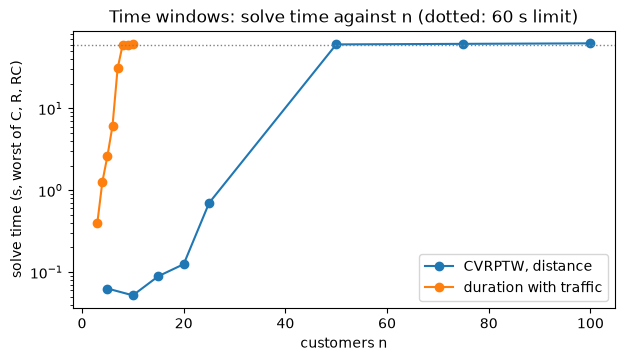

In [4]:
gap = (100 * (td.objective - td.bound) / td.objective).clip(lower=0)
td["bound_gap"] = gap.where(td.bound > 0)  # n/a when the bound is not positive
display(td[["instance", "n", "status", "seconds", "objective", "bound", "bound_gap", "lp_bound",
            "variables"]].round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for label, df in [("CVRPTW, distance", tw), ("duration with traffic", td)]:
    m = df.groupby("n").seconds.max()
    ax.plot(m.index, m.values, marker="o", label=label)
ax.axhline(60, color="grey", ls=":", lw=1)
ax.set(yscale="log", xlabel="customers n", ylabel="solve time (s, worst of C, R, RC)",
       title="Time windows: solve time against n (dotted: 60 s limit)")
ax.legend()
plt.show()

**Reading 4.3.** The model with traffic proves the optimum up to 7 customers on every instance
(8 on C101 and R101), then stops at the 60 s limit with a bound far below the solution. Its LP
relaxation is useless as a bound: with $x$ fractional, the big-M of (8) is switched off, every
truck "returns" at $e_0$ and leaves at $l_0$, and the LP value is $-n\,(l_0 - e_0)$. One departure
hour per stop multiplies the variables by 24 (48 here) and the big-M keeps the relaxation weak, so the exact model with traffic serves to check the
definition of the objective on small cases (section 3), not to plan a day.

**Where the exact approach stops.** Without windows: MTZ at 10 to 14 customers; flow and capacity
cuts solve every tested size (up to 16, at most 4.4 s), so their limit lies beyond. With windows, without traffic: 100 customers when the windows
are tight on clustered or random customers (C101, R101), fewer than 50 on mixed RC101. With
traffic: 7 to 8 customers. Beyond that, the metaheuristics of sections 5 to 8 give the solutions,
and the ILP values of 4.2 remain the reference used to measure their gap.

<a id="s5"></a>
## 5. Chosen metaheuristic: GRASP-ILS

Three metaheuristics from the course list were implemented on the same instance, solution and
evaluator code and compared under one protocol (section 8): **Tabu Search** (Pablo,
`src/cvrp/tabu.py`), **Simulated Annealing** (Dag, `src/cvrp/sa.py`, compiled with numba) and
**GRASP** with an iterated local search inside each iteration (Farida, `src/cvrp/grasp.py`). The
rule fixed before the campaign was: feasible on every run, then lowest mean gap, then lowest mean
time. GRASP-ILS is feasible on all 500 test runs and has the lowest mean gap (1.16 %, against
1.70 % for SA and 3.98 % for Tabu Search), with every pairwise difference significant: it is the
chosen method. Its full study is `notebooks/04_grasp.ipynb`.

| Component | GRASP-ILS |
| --- | --- |
| Encoding | a list of routes, each a list of customers; the depot is implicit at both ends |
| Initialization | randomized adaptive parallel insertion: each unrouted customer keeps its cheapest feasible insertion per route; score = regret $c_1 - (c_2 - c_1)$; a customer is drawn from the restricted candidate list $\{u : \text{score}(u) \le s_{\min} + \alpha (s_{\max} - s_{\min})\}$; a new route starts from a customer far from the depot or with an early due time; if more than $K$ routes are opened, the smallest ones are emptied and reinserted |
| Neighborhoods | relocate, swap, 2-opt*, Or-opt (chains of 2 or 3), cross-exchange (segments up to 2), 2-opt; only between a customer and its 20 nearest customers (granular) |
| Local search | variable neighborhood descent: after any improvement restart from the first neighborhood; first improvement |
| Time windows | each route stores the earliest start $A_k$ and the latest feasible start $Z_k$ of every position (Savelsbergh, 1992), so a move is checked in $O(1)$ plus the moved segment; intra-route 2-opt re-checks the route |
| Guidance | multi-start (diversification) by the randomized construction; intensification by 90 kicks per iteration: remove a cluster of 10 to 20 % of the customers, reinsert them at their cheapest place, descend, keep only if shorter |
| Acceptance | a solution replaces the best only if it is feasible for the shared evaluator and shorter |
| Stopping criterion | wall-clock time limit (20 s in the benchmark), checked between iterations and kicks |
| Parameters | $\alpha = 0.3$, first improvement, 90 kicks: the best of 12 settings on the 6 tuning instances (section 8.1) |
| Objective | a parameter: total distance (benchmark) or total route duration with hourly traffic, the objective of section 3 (`objective="duration"`) |

The two other algorithms, for the comparison of section 8:

| Component | Tabu Search | Simulated Annealing |
| --- | --- | --- |
| Encoding | list of routes | list of routes (arrays, compiled with numba) |
| Initialization | time-oriented nearest neighbor (Solomon, 1987) | randomized cheapest feasible insertion |
| Neighborhood | relocate, swap, 2-opt*, 2-opt between a customer and one of its 15 nearest | relocate a customer or a chain of 2 or 3, swap, 2-opt, 2-opt*, between random routes |
| Step | best non-tabu move among 200 sampled | one random feasible move |
| Guidance | a moved customer is tabu for a tenure drawn in $[t/2, 3t/2]$; aspiration if a tabu move gives a new best | Metropolis acceptance, $T(\tau) = T_0 (T_f / T_0)^{\tau}$, $\tau$ = elapsed fraction of the time limit, $T_0 = \max(1, f \cdot \text{start cost})$ |
| Stopping | time limit | time limit |
| Tuned | tenure $t = 20$, 200 candidates (grid of 9) | $f = 0.005$, $T_f = 0.005$ (grid of 12) |
| Fixed | 15 nearest neighbors | move probabilities (uniform) |

<a id="s6"></a>
## 6. Implementation

`grasp(inst, GRASPParams(...), seed)` reads the shared `Instance`, returns a `GRASPResult`
(best `Solution`, cost, runtime, iterations, per-iteration history) and re-checks the kept
solution with `Solution.violations`, independent of the internal caches. The demo runs the chosen
parameters for 5 s on one instance of each family (clustered, random, mixed), with the distances
of the benchmark.

GRASPParams(alpha=0.3, iterations=1000000000, improvement='first', enhanced=True, max_local_rounds=100000, n_neighbors=20, construction='regret', tw_weight=0.0, perturb_kicks=90, time_limit=5.0, objective='distance', start_min=480.0)


,instance,routes,cost,best known,gap %,iterations,seconds,feasible
0,C105,10,827.3,827.3,0.00,10,5.0,True
1,R205,4,968.8,949.8,2.00,8,5.0,True
2,RC105,16,1531.0,1513.7,1.14,6,5.0,True


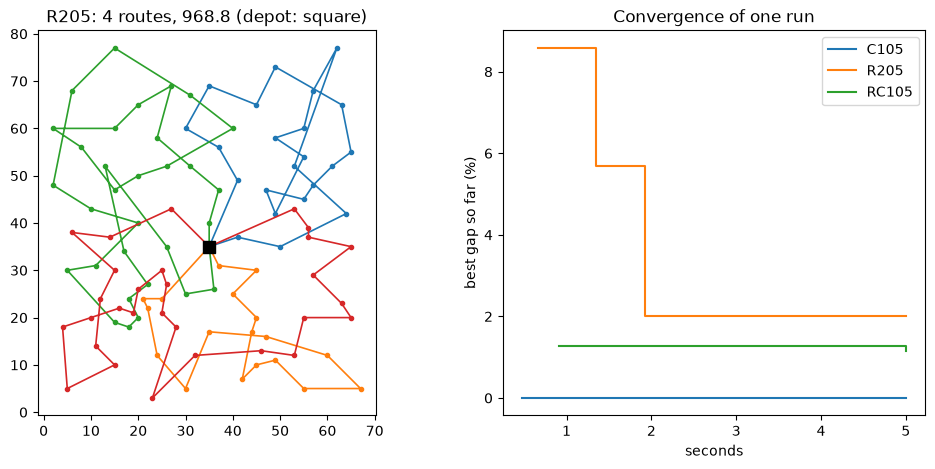

In [5]:
import solomon_study as study
from cvrp.grasp import GRASPParams, grasp

CHOSEN = {"alpha": 0.3, "improvement": "first", "perturb_kicks": 90}
params = GRASPParams(iterations=10**9, time_limit=5.0, **CHOSEN)
print(params)

demo, runs = [], {}
for name in ["C105", "R205", "RC105"]:
    inst = study.load(name)
    res = grasp(inst, params, seed=1)
    runs[name] = (inst, res)
    demo.append({"instance": name, "routes": len(res.best), "cost": round(res.cost, 1),
                 "best known": inst.best_known,
                 "gap %": round(100 * (res.cost - inst.best_known) / inst.best_known, 2),
                 "iterations": res.iterations, "seconds": round(res.runtime, 1),
                 "feasible": res.best.is_feasible(inst)})
display(pd.DataFrame(demo))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
inst, res = runs["R205"]
for k, route in enumerate(res.best.routes):
    path = [0, *route, 0]
    axes[0].plot(*inst.coords[path].T, "-o", ms=3, lw=1.2, color=plt.cm.tab10(k % 10))
axes[0].plot(*inst.coords[0], "ks", ms=9)
axes[0].set(title=f"R205: {len(res.best)} routes, {res.cost:.1f} (depot: square)", aspect="equal")
for name, (inst, res) in runs.items():
    h = pd.DataFrame(res.history)
    axes[1].step(h.seconds, 100 * (h.best - inst.best_known) / inst.best_known, where="post",
                 label=name)
axes[1].set(xlabel="seconds", ylabel="best gap so far (%)", title="Convergence of one run")
axes[1].legend()
plt.show()

In 5 s every run is feasible and within a few percent of the best known value; most of the gain
comes in the first iterations, and the later ones polish the solution through the kicks.

<a id="s7"></a>
## 7. Test cases

The automated tests (`pytest`, 76 tests) cover the shared evaluator, every solver and the
models: known optimum of a hand-made 4-customer instance (`tests/conftest.py`, cost
$10 + \sqrt{2}$), agreement between the fast time-window checks of GRASP and the shared evaluator,
reproducibility with a seed, a local search that never worsens, the traffic cost of GRASP equal to
the Tabu Search duration, and the exact optimum of the toy instance of notebook 01 (section 3).

The cell below checks GRASP-ILS against the **proven optima** of section 4.2: the first 10, 25 and
50 customers of C101, R101 and RC101, 2 s per run.

In [6]:
from exact_study import head, solomon

opt = pd.read_csv(RES / "exact_cvrptw.csv").set_index("instance")
quick = GRASPParams(iterations=10**9, time_limit=2.0, **CHOSEN)
rows = []
for name in ["C101", "R101", "RC101"]:
    for n in [10, 25, 50]:
        inst = head(solomon(name), n, fleet=n)
        res = grasp(inst, quick, seed=1)
        ref = opt.loc[inst.name]
        diff = round(100 * (res.cost - ref.objective) / ref.objective, 2) + 0.0
        rows.append({"instance": inst.name, "ILP": round(ref.objective, 1),
                     "ILP status": ref.status, "GRASP-ILS (2 s)": round(res.cost, 1),
                     "difference %": diff, "feasible": res.best.is_feasible(inst)})
display(pd.DataFrame(rows))

,instance,ILP,ILP status,GRASP-ILS (2 s),difference %,feasible
0,C101[:10],58.1,Optimal,58.1,0.00,True
1,C101[:25],191.3,Optimal,191.3,0.00,True
2,C101[:50],362.4,Optimal,362.4,0.00,True
3,R101[:10],269.2,Optimal,269.2,0.00,True
4,R101[:25],617.1,Optimal,617.1,0.00,True
5,R101[:50],1044.0,Optimal,1044.0,0.00,True
6,RC101[:10],185.5,Optimal,185.5,0.00,True
7,RC101[:25],461.1,Optimal,461.1,0.00,True
8,RC101[:50],970.9,TimeLimit,957.1,-1.42,True


GRASP-ILS finds the proven optimum on all eight sub-instances where the ILP proves one, and on
RC101 with 50 customers it is 1.4 % shorter than the best solution the ILP finds in 60 s.

<a id="s8"></a>
## 8. Experimental study

**Questions.** Which metaheuristic gives the lowest gap to the best known solution at equal time?
Is the difference significant, and does it hold on every family of instances?

| Item | Value |
| --- | --- |
| Instances | the 56 Solomon CVRPTW instances, 100 customers (C1, C2, R1, R2, RC1, RC2) |
| Distances | Euclidean, truncated to one decimal, the convention of the best known values (checked on all 56) |
| Objective | total distance, travel time = distance, no traffic (section 3) |
| Tuning set | C101, C201, R101, R201, RC101, RC201, seeds 101 and 102 |
| Test set | the other 50 instances, seeds 1 to 10: 500 runs per algorithm |
| Budget | 20 s of wall-clock time per run, construction included, the same for every algorithm |
| Machine | one Apple M2 (8 cores), 7 runs in parallel, Python 3.13; the jobs of the three algorithms are interleaved |
| Metric | gap $= 100\,(\text{cost} - \text{BKS}) / \text{BKS}$; GRASP-ILS and SA solutions checked by the shared evaluator, Tabu Search ones by its cost function (capacity, windows, return to the depot), and every solution for coverage and cost |
| Target | the brief caps the grade when the gap exceeds 7 to 10 %; 7 % is the stricter reading |
| Tests | Friedman on the per-instance mean gaps, then Wilcoxon signed rank per pair with Holm correction, 5 % |

`python experiments/solomon_study.py tune`, then `run`, writes the two CSV files read below.

<a id="s81"></a>
### 8.1 Tuning

In [7]:
tuning = pd.read_csv(RES / "solomon_tuning.csv")
bench = pd.read_csv(RES / "solomon_benchmark.csv")
NAMES = {"grasp": "GRASP-ILS", "sa": "SA", "tabu": "Tabu Search"}
COLORS = {"grasp": "#2a78d6", "sa": "#eb6834", "tabu": "#1baf7a"}
pd.set_option("display.max_colwidth", None)

t = tuning.groupby(["algorithm", "params"]).gap.mean().reset_index()
chosen = t.loc[t.groupby("algorithm").gap.idxmin()].set_index("algorithm")
chosen["settings tried"] = t.groupby("algorithm").size()
chosen["worst setting gap"] = t.groupby("algorithm").gap.max()
display(chosen.rename(index=NAMES, columns={"gap": "tuning gap %"}).round(2))

,params,tuning gap %,settings tried,worst setting gap
algorithm,,,,
GRASP-ILS,"{'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}",1.17,12,3.13
SA,"{'initial_temperature_factor': 0.005, 'final_temperature': 0.005}",0.56,12,0.78
Tabu Search,"{'tenure': 20, 'candidates': 200}",2.11,9,9.96


Each algorithm keeps the setting with the lowest mean gap on the tuning set only. The spread
between the best and the worst setting is large for Tabu Search (the candidate list size matters)
and for GRASP (the kicks matter), and small for SA, whose 12 temperature settings stay within
0.3 points. SA is best on the tuning set (0.56 % against 1.17 %); the test set, nine times larger,
decides.

<a id="s82"></a>
### 8.2 Results on the 50 test instances

In [8]:
assert bench.feasible.all() and len(bench) == 1500
bench["class"] = bench.instance.str.extract(r"^([A-Z]+\d)")[0]
overall = bench.groupby("algorithm").agg(
    mean_gap=("gap", "mean"),
    std_gap=("gap", "std"),
    median_gap=("gap", "median"),
    worst_gap=("gap", "max"),
    runs_at_bks=("gap", lambda g: int((g <= 1e-6).sum())),
    runs_within_7=("gap", lambda g: 100 * (g <= 7).mean()),
    routes=("routes", "mean"),
    seconds=("seconds", "mean"),
).sort_values("mean_gap")
display(overall.rename(index=NAMES).round(2))

by_class = bench.pivot_table(index="class", columns="algorithm", values="gap", aggfunc="mean")
display(by_class[["grasp", "sa", "tabu"]].rename(columns=NAMES).round(2))

,mean_gap,std_gap,median_gap,worst_gap,runs_at_bks,runs_within_7,routes,seconds
algorithm,,,,,,,,
GRASP-ILS,1.16,1.41,0.68,9.82,162,99.2,8.00,20.01
SA,1.70,1.43,1.58,6.51,106,100.0,8.91,20.01
Tabu Search,3.98,3.15,3.96,14.03,110,83.2,9.09,20.00


algorithm,GRASP-ILS,SA,Tabu Search
class,,,
C1,0.02,0.44,0.78
C2,0.01,0.73,1.26
R1,0.68,1.59,3.54
R2,2.22,2.37,5.78
RC1,1.30,2.39,5.62
RC2,2.73,2.65,6.82


GRASP-ILS has the lowest mean (1.16 %) and median gap and reaches the best known value on 162 of
its 500 runs; SA has the smallest worst case (6.5 %, every run within 7 %); Tabu Search is about
3.4 times the mean gap of GRASP-ILS. By class, GRASP-ILS is best on five of six; on RC2,
mixed customers with long routes, SA is slightly ahead (2.65 % against 2.73 %). Type 2 classes
(few long routes) are the hardest for all three.

In [9]:
per_inst = bench.groupby(["instance", "algorithm"]).gap.agg(["mean", "std", "min"]).unstack()
per_inst.columns = [f"{NAMES[a]} {s}" for s, a in per_inst.columns]
seed_std = bench.groupby(["instance", "algorithm"]).gap.std().unstack().mean()
print("mean over instances of the seed std (gap points):",
      ", ".join(f"{NAMES[a]} {v:.2f}" for a, v in seed_std.items()))
order = [f"{NAMES[a]} {s}" for a in ["grasp", "sa", "tabu"] for s in ["mean", "std", "min"]]
display(per_inst[order].round(2))

mean over instances of the seed std (gap points): GRASP-ILS 0.47, SA 0.78, Tabu Search 1.45


,GRASP-ILS mean,GRASP-ILS std,GRASP-ILS min,SA mean,SA std,SA min,Tabu Search mean,Tabu Search std,Tabu Search min
instance,,,,,,,,,
C102,0.00,0.00,0.00,0.49,0.42,0.00,0.81,1.44,0.00
C103,0.00,0.00,0.00,1.80,1.44,0.00,3.28,2.50,1.10
C104,0.17,0.24,0.00,0.57,1.04,0.00,2.16,1.62,0.46
C105,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00
C106,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
C107,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
C108,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
C109,0.00,0.00,0.00,0.63,1.33,0.00,0.00,0.00,0.00
C202,0.00,0.00,0.00,1.23,2.00,-0.00,0.00,0.00,-0.00


Per instance (mean, seed standard deviation and best over 10 seeds): GRASP-ILS is also the most
stable from one seed to the next (0.47 points against 0.78 for SA and 1.45 for Tabu Search), and
its best run reaches the best known value on all 15 C instances and on 5 of the 11 R1 ones.

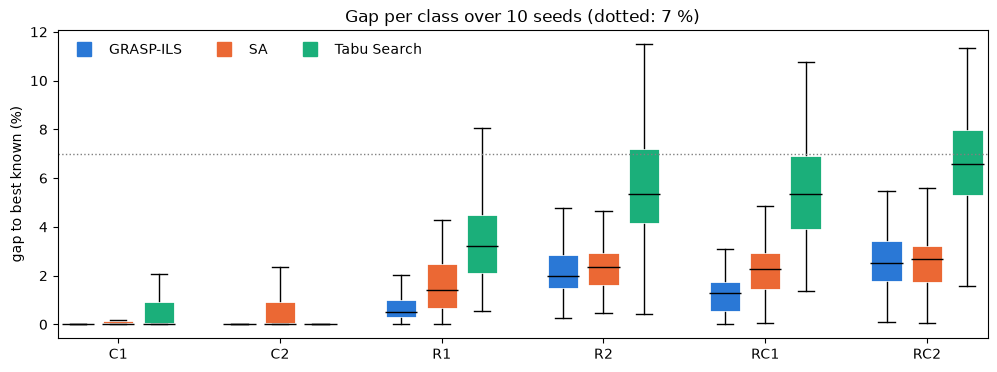

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
classes = sorted(bench["class"].unique())
for k, algo in enumerate(["grasp", "sa", "tabu"]):
    data = [bench[(bench["class"] == c) & (bench.algorithm == algo)].gap for c in classes]
    bp = ax.boxplot(data, positions=[i * 4 + k for i in range(len(classes))], widths=0.8,
                    patch_artist=True, showfliers=False)
    for box in bp["boxes"]:
        box.set(facecolor=COLORS[algo], edgecolor="white", linewidth=2)
    for med in bp["medians"]:
        med.set(color="black")
    ax.plot([], [], "s", color=COLORS[algo], ms=10, label=NAMES[algo])
ax.set_xticks([i * 4 + 1 for i in range(len(classes))], classes)
ax.axhline(7, color="grey", ls=":", lw=1)
ax.set(ylabel="gap to best known (%)", title="Gap per class over 10 seeds (dotted: 7 %)")
ax.legend(ncol=3, frameon=False)
plt.show()

The boxes show the spread over instances and seeds: GRASP-ILS is nearly always at the best known
value on the clustered classes, and its spread grows on the random and mixed type 2 classes, where
SA is as good. Outliers are hidden; the worst runs are in the table above.

<a id="s83"></a>
### 8.3 Statistical tests

In [11]:
from scipy.stats import friedmanchisquare, wilcoxon

means = bench.groupby(["instance", "algorithm"]).gap.mean().unstack()
stat, p = friedmanchisquare(means.grasp, means.sa, means.tabu)
print(f"Friedman on 50 instances: chi2 = {stat:.1f}, p = {p:.1e}")
pairs = []
for a, b in itertools.combinations(["grasp", "sa", "tabu"], 2):
    w, pv = wilcoxon(means[a], means[b])
    pairs.append({"pair (A vs B)": f"{NAMES[a]} vs {NAMES[b]}", "W": w, "p": pv,
                  "A better on": int((means[a] < means[b] - 1e-9).sum()),
                  "B better on": int((means[b] < means[a] - 1e-9).sum()),
                  "ties": int((abs(means[a] - means[b]) <= 1e-9).sum()),
                  "n used": int((abs(means[a] - means[b]) > 1e-9).sum())})
pairs = pd.DataFrame(pairs).sort_values("p").reset_index(drop=True)
m = len(pairs)
pairs["Holm p"] = (pairs.p * (m - pairs.index)).cummax().clip(upper=1)
pairs["significant at 5 %"] = pairs["Holm p"] < 0.05
display(pairs.style.format({"W": "{:.0f}", "p": "{:.1e}", "Holm p": "{:.1e}"}))

Friedman on 50 instances: chi2 = 57.1, p = 4.0e-13


,pair (A vs B),W,p,A better on,B better on,ties,n used,Holm p,significant at 5 %
0,GRASP-ILS vs Tabu Search,0,2.4e-08,41,0,9,41,7.3e-08,True
1,SA vs Tabu Search,19,2.8e-08,40,4,6,44,7.3e-08,True
2,GRASP-ILS vs SA,194,7.5e-04,31,12,7,43,7.5e-04,True


The three algorithms differ (Friedman), and every pair differs after the Holm correction (the
Wilcoxon test drops tied instances, hence "n used"):
GRASP-ILS beats SA on 31 instances, SA beats it on 12, and 7 are ties (instances solved to the best
known value by both); GRASP-ILS is never worse than Tabu Search (better on 41, 9 ties) and SA is
better than it on 40 instances, worse on 4.

**Behavior.** The three spend the 20 s very differently: SA makes about 42 million compiled move
attempts, Tabu Search about 18 000 iterations of 200 sampled moves, GRASP-ILS about 19 iterations
of construction, descent and 90 kicks. Few deep searches from good starts beat many cheap moves
here. Tabu Search makes a similar number of iterations on every class (about 16 100 to 20 100), so
its larger gap on type 2 is not a matter of speed. SA is compiled and the others are not, so "equal time" mixes the
algorithm with its implementation: this favors SA, which still comes second.

**Conclusion.** GRASP-ILS is chosen: feasible on every run, mean gap 1.16 %, significantly better
than SA and Tabu Search, and within the 7 % target on 99.2 % of its runs (worst run 9.8 %, RC2).

<a id="s9"></a>
## 9. Limitations and improvements

- **Traffic is not benchmarked.** Published best known values exist only for distance without
  traffic; the model with traffic is solved exactly up to 7 or 8 customers (section 4.3) and the
  metaheuristics accept it as an objective, but no reference exists to measure their gap. With
  measured traffic data, the next step is to compare GRASP-ILS with the ILP on small cases, as in
  section 7, then with a lower bound on larger ones.
- **Departure time.** The model lets each truck choose its departure; the traffic mode of the
  metaheuristics fixes one departure time for the fleet. Optimizing it per route is a
  one-dimensional search per route.
- **First in, first out.** The travel time depends on the departure hour only, so a later departure
  can arrive earlier; cutting each trip at the full hour would remove it.
- **Size.** All benchmark instances have 100 customers; the scaling to the 200 to 1000 customers
  of the Homberger instances is not measured.
- **Equal time is not equal implementation.** SA is compiled, the other two are pure Python;
  compiling the descent of GRASP-ILS (numba) would give it more iterations in the same time.
- **Fleet.** The benchmark minimizes distance only and leaves the number of trucks free; an operator
  who pays per truck would add it to the objective (it is not in the model of section 3).
- **Tuning.** Two seeds on six instances; the SA settings are within noise of each other. The
  number of kicks of GRASP-ILS was only tested at 0 and 90, and the kick size (10 to 20 %), the
  neighbor lists (20 for GRASP, 15 for Tabu Search) are fixed; three chosen values sit at the edge
  of their grid (90 kicks, tenure 20, $T_f = 0.005$), so a wider grid could still improve them.
- **Hardware.** The M2 has 4 performance and 4 efficiency cores: with 7 parallel runs, equal wall
  clock time is not exactly equal compute, although the interleaved jobs spread this evenly.

<a id="s10"></a>
## 10. References

- Dantzig, G. B., Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80-91.
- Feo, T. A., Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6, 109-133.
- Friedman, M. (1937). The use of ranks to avoid the assumption of normality. *Journal of the American Statistical Association*, 32, 675-701.
- Garey, M. R., Johnson, D. S. (1979). *Computers and Intractability*. Freeman.
- Gavish, B., Graves, S. C. (1978). The travelling salesman problem and related problems. Working paper GR-078-78, MIT.
- Glover, F. (1986). Future paths for integer programming and links to artificial intelligence. *Computers and Operations Research*, 13(5), 533-549.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6, 65-70.
- Ichoua, S., Gendreau, M., Potvin, J.-Y. (2003). Vehicle dispatching with time-dependent travel times. *European Journal of Operational Research*, 144(2), 379-396.
- Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations*, 85-103.
- Kirkpatrick, S., Gelatt, C. D., Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671-680.
- Miller, C. E., Tucker, A. W., Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326-329.
- Resende, M. G. C., Ribeiro, C. C. (2010). Greedy randomized adaptive search procedures: advances, hybridizations, and applications. In *Handbook of Metaheuristics*, Springer, 283-319.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146-154.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
- Toth, P., Vigo, D. (2003). The granular tabu search and its application to the vehicle routing problem. *INFORMS Journal on Computing*, 15(4), 333-346.
- Toth, P., Vigo, D. (2014). *Vehicle Routing: Problems, Methods, and Applications*, 2nd ed. SIAM.
- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin*, 1(6), 80-83.
- Benchmark data: Solomon instances, PyVRP/VRPLIB copy, github.com/PyVRP/VRPLIB.

<a id="sA"></a>
## A. Glossary of symbols

**Model (sections 1 to 4)**

| Symbol | Meaning | Unit or domain |
| --- | --- | --- |
| $n$ | number of customers | integer |
| $V^+ = \{1, \dots, n\}$ | customers | set |
| $0$, $n + 1$ | the depot as departure and as return | nodes |
| $V$ | all nodes, $\{0\} \cup V^+ \cup \{n+1\}$ | set |
| $A$ | allowed trips (arcs) $(i, j)$ | set of pairs |
| $\mathcal{K}$, $K$ | the trucks, their number | set, integer |
| $\mathcal{H}$, $h$ | hours of the day, one hour | $\{0, \dots, 23\}$ |
| $Q$ | capacity of a truck | units |
| $q_i$ | demand of customer $i$ | units |
| $e_i$, $l_i$ | opening and closing of the window of $i$ (service must start in it) | min after midnight |
| $e_0$, $l_0$ | start and end of the working day | min |
| $s_i$ | service time at $i$ | min |
| $c_{ij}$ | travel time $i \to j$ on empty roads | min |
| $\rho_h$ | traffic intensity of hour $h$ | $\ge 1$ |
| $c_{ij}^h = \rho_h c_{ij}$ | travel time $i \to j$ when leaving during hour $h$ | min |
| $M$ | big number that switches a constraint off (2880, two days) | min |
| $x_{ij}^k$ | 1 if truck $k$ drives directly from $i$ to $j$ | $\{0, 1\}$ |
| $y_{ih}$, $y_{0h}^k$ | 1 if the truck leaves customer $i$ (the depot, truck $k$) during hour $h$ | $\{0, 1\}$ |
| $t_0^k$, $t_{n+1}^k$ | departure from and return to the depot of truck $k$ | min |
| $a_i$, $w_i$, $t_i$ | arrival, waiting, service start at customer $i$ | min |
| $z$ | total route duration (objective) | min |
| $B$ | bound of the decision version (section 2) | min |
| $x_{ij}$, $u_i$, $f_{ij}$ | two-index arc variable, MTZ load, load on board (section 4.1) | binary, units |
| $S$, $q(S)$ | a set of customers, its total demand (capacity cuts) | set, units |
| $z^*$, $z_{LP}$ | best integer value, LP relaxation value | same unit as $z$ |

**Metaheuristics (sections 5 and 6)**

| Symbol | Meaning |
| --- | --- |
| $\alpha$ | GRASP greediness: 0 picks the best candidate, 1 a random one |
| $c_1(u)$, $c_2(u)$ | cheapest and second cheapest insertion cost of customer $u$ |
| regret | $c_1 - (c_2 - c_1)$: low when $u$ has one clearly best place |
| RCL | restricted candidate list, the customers whose score is within $\alpha$ of the best |
| $s_{\min}$, $s_{\max}$ | best and worst score of the unrouted customers |
| $A_k$, $Z_k$ | earliest and latest feasible service start at position $k$ of a route |
| kicks | perturbations per GRASP iteration (remove 10 to 20 % of the customers, reinsert) |
| $t$ (tenure) | iterations a moved customer stays tabu |
| $T_0$, $T_f$, $f$ | initial and final temperature of SA, $T_0 = \max(1, f \cdot \text{start cost})$ |
| $\tau$ | elapsed fraction of the time limit, from 0 to 1 |

**Experimental study (section 8)**

| Symbol | Meaning |
| --- | --- |
| BKS | best known solution of a benchmark instance, from the literature |
| gap | $100\,(\text{cost} - \text{BKS}) / \text{BKS}$, in % |
| seed | initial value of the random generator; 10 seeds = 10 independent runs |
| std | standard deviation over the runs |
| Friedman $\chi^2$ | test that the algorithms have the same ranks over the instances |
| Wilcoxon $W$ | paired test between two algorithms over the instances |
| $p$, Holm $p$ | probability of a difference this large by chance; corrected for three comparisons |